Lesson 1 — Challenge 1: Quantum Measurement Quality vs Application-Level Quality
How can QFlowPilot determine whether a quantum computation has produced a sufficiently reliable result for the application that requested it?

We will study this from the mathematical foundation to a working Qiskit Aer experiment.

By the end of this lesson, you should understand:
1. What quantum measurements and shots mean.
2. How a quantum computer produces measurement probabilities.
3. How to calculate the mean, variance and standard error.
4. How to calculate confidence intervals.
5. The difference between measurement uncertainty and application-level quality.
6. How to implement these concepts using Qiskit Aer.
7. How these measurements will be used by QFlowPilot.

In [1]:

import numpy as np
import pandas as pd

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator


# --------------------------------------------------
# 1. Create a quantum circuit
# --------------------------------------------------

qc = QuantumCircuit(1, 1)

# Hadamard gate: create equal superposition
qc.h(0)

# Measure qubit 0 into classical bit 0
qc.measure(0, 0)

print("Quantum circuit:")
print(qc.draw())


# --------------------------------------------------
# 2. Initialize Aer simulator
# --------------------------------------------------

simulator = AerSimulator()

compiled_circuit = transpile(qc, simulator)


# --------------------------------------------------
# 3. Define shot counts
# --------------------------------------------------

shot_values = [100, 500, 1000, 5000, 10000]

results = []


# --------------------------------------------------
# 4. Execute circuit and calculate statistics
# --------------------------------------------------

for shots in shot_values:

    job = simulator.run(
        compiled_circuit,
        shots=shots,
        memory=True,
        seed_simulator=42
    )

    result = job.result()

    # Individual measurement outcomes
    memory = result.get_memory(compiled_circuit)

    # Convert bitstrings to numerical values
    # 0 -> +1 (Z observable)
    # 1 -> -1 (Z observable)

    measurements = np.array([
        1 if bit == "0" else -1
        for bit in memory
    ])

    # Estimated expectation value
    mean = np.mean(measurements)

    # Sample variance
    variance = np.var(measurements, ddof=1)

    # Sample standard deviation
    std = np.sqrt(variance)

    # Standard error
    standard_error = std / np.sqrt(shots)

    # Approximate 95% confidence interval
    ci_lower = mean - 1.96 * standard_error
    ci_upper = mean + 1.96 * standard_error

    # Measurement probabilities
    counts = result.get_counts(compiled_circuit)

    p0 = counts.get("0", 0) / shots
    p1 = counts.get("1", 0) / shots

    results.append({
        "shots": shots,
        "count_0": counts.get("0", 0),
        "count_1": counts.get("1", 0),
        "P(0)": p0,
        "P(1)": p1,
        "mean_Z": mean,
        "variance": variance,
        "std": std,
        "standard_error": standard_error,
        "CI_lower": ci_lower,
        "CI_upper": ci_upper
    })


# --------------------------------------------------
# 5. Display results
# --------------------------------------------------

df = pd.DataFrame(results)

print("\nQuantum Measurement Statistics:")
print(df.to_string(index=False))


# --------------------------------------------------
# 6. Compare estimated and theoretical values
# --------------------------------------------------

print("\nTheoretical expectation value of Z = 0")
print("Theoretical probability P(0) = 0.5")
print("Theoretical probability P(1) = 0.5")


Quantum circuit:
     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 

Quantum Measurement Statistics:
 shots  count_0  count_1   P(0)   P(1)  mean_Z  variance      std  standard_error  CI_lower  CI_upper
   100       49       51 0.4900 0.5100 -0.0200  1.009697 1.004837        0.100484 -0.216948  0.176948
   500      260      240 0.5200 0.4800  0.0400  1.000401 1.000200        0.044730 -0.047671  0.127671
  1000      514      486 0.5140 0.4860  0.0280  1.000216 1.000108        0.031626 -0.033987  0.089987
  5000     2483     2517 0.4966 0.5034 -0.0068  1.000154 1.000077        0.014143 -0.034521  0.020921
 10000     4921     5079 0.4921 0.5079 -0.0158  0.999850 0.999925        0.009999 -0.035399  0.003799

Theoretical expectation value of Z = 0
Theoretical probability P(0) = 0.5
Theoretical probability P(1) = 0.5


. Variance
\[
\operatorname{Var}(X)=E[X^2]-E[X]^2
\]

2. Standard error
\[
SE=\frac{s}{\sqrt{N}}
\]

3. Approximate 95% confidence interval
\[
CI_{95\%}=\hat{\mu}\pm1.96SE
\]


OPTIMIZED QAOA PARAMETERS
-------------------------
Gamma: 5.497768631428436
Beta: 1.1781044427185814
Exact expected cut: 2.9999999989001376

EXACT APPLICATION QUALITY
-------------------------
Optimal bitstrings: ['0101', '1010']
Exact optimal probability: 0.5312505141574215

QAOA APPLICATION QUALITY RESULTS
--------------------------------
 shots  mean_cut  approximation_ratio  optimal_probability  variance  standard_error  AR_CI_lower  AR_CI_upper  Popt_CI_lower  Popt_CI_upper
   100    2.9800              0.74500               0.5400  1.413737        0.118901     0.686739     0.803261       0.442647       0.634394
   500    3.0080              0.75200               0.5300  1.210357        0.049201     0.727892     0.776108       0.486190       0.573353
  1000    3.0060              0.75150               0.5300  1.217181        0.034888     0.734405     0.768595       0.499010       0.560761
  5000    3.0096              0.75240               0.5382  1.267361        0.015921     0.

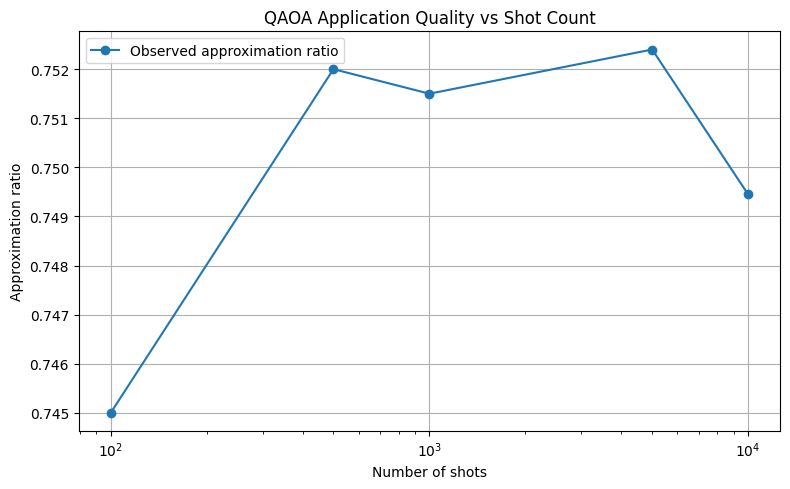

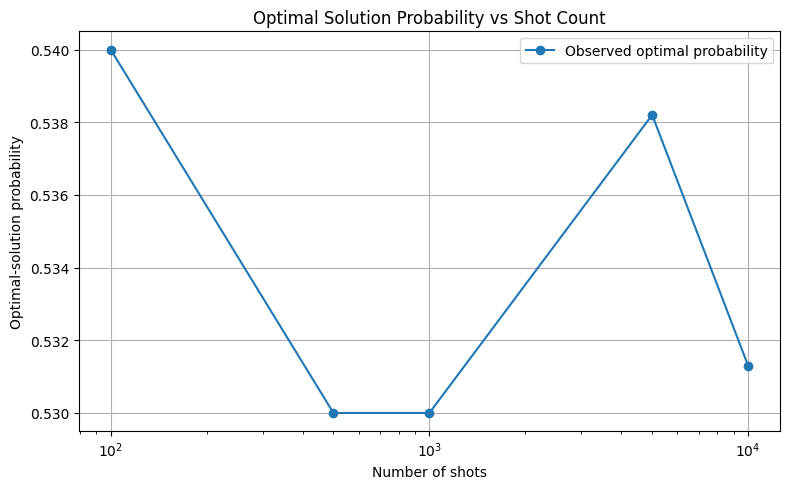


Experiment completed successfully.


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import differential_evolution

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator


# ==========================================================
# 1. DEFINE THE MAX-CUT GRAPH
# ==========================================================

N_QUBITS = 4

EDGES = [
    (0, 1),
    (1, 2),
    (2, 3),
    (3, 0)
]

SHOTS_LIST = [100, 500, 1000, 5000, 10000]

OPTIMAL_CUT = 4


# ==========================================================
# 2. CLASSICAL MAX-CUT OBJECTIVE
# ==========================================================

def cut_value(bitstring):

    # Qiskit displays bitstrings in reverse qubit order.
    # Convert q3q2q1q0 into x0,x1,x2,x3.

    bits = [int(b) for b in bitstring[::-1]]

    cut = 0

    for i, j in EDGES:
        cut += bits[i] ^ bits[j]

    return cut


# ==========================================================
# 3. BUILD QAOA CIRCUIT
# ==========================================================

def build_qaoa_circuit(gamma, beta, measurements=False):

    qc = QuantumCircuit(N_QUBITS, N_QUBITS if measurements else 0)

    # Initial state: |+>^n

    for q in range(N_QUBITS):
        qc.h(q)

    # Cost Hamiltonian:
    # H_C = sum((I - Z_i Z_j) / 2)
    #
    # RZZ(-gamma) implements the cost evolution
    # up to a global phase.

    for i, j in EDGES:
        qc.rzz(-gamma, i, j)

    # Mixer Hamiltonian:
    # H_B = sum(X_i)
    #
    # exp(-i beta X) = RX(2 beta)

    for q in range(N_QUBITS):
        qc.rx(2 * beta, q)

    # Measurement

    if measurements:
        qc.measure(range(N_QUBITS), range(N_QUBITS))

    return qc


# ==========================================================
# 4. CALCULATE EXACT EXPECTED CUT USING STATEVECTOR
# ==========================================================

def exact_expected_cut(parameters):

    gamma, beta = parameters

    circuit = build_qaoa_circuit(
        gamma,
        beta,
        measurements=False
    )

    state = Statevector.from_instruction(circuit)

    probabilities = state.probabilities_dict()

    expected_cut = 0.0

    for bitstring, probability in probabilities.items():

        value = cut_value(bitstring)

        expected_cut += probability * value

    return expected_cut


# ==========================================================
# 5. OPTIMIZE QAOA PARAMETERS
# ==========================================================

def objective(parameters):

    # Differential Evolution minimizes.
    # We minimize negative expected cut.

    return -exact_expected_cut(parameters)


optimization = differential_evolution(
    objective,
    bounds=[
        (0, 2 * np.pi),  # gamma
        (0, np.pi)       # beta
    ],
    seed=42,
    maxiter=100,
    popsize=10,
    tol=1e-7
)

gamma_opt, beta_opt = optimization.x

print("\nOPTIMIZED QAOA PARAMETERS")
print("-------------------------")
print("Gamma:", gamma_opt)
print("Beta:", beta_opt)

print(
    "Exact expected cut:",
    exact_expected_cut(optimization.x)
)


# ==========================================================
# 6. EXACT OPTIMAL-SOLUTION PROBABILITY
# ==========================================================

optimal_strings = []

for number in range(2 ** N_QUBITS):

    bitstring = format(number, f"0{N_QUBITS}b")

    if cut_value(bitstring) == OPTIMAL_CUT:
        optimal_strings.append(bitstring)

exact_circuit = build_qaoa_circuit(
    gamma_opt,
    beta_opt,
    measurements=False
)

exact_state = Statevector.from_instruction(exact_circuit)

exact_probabilities = exact_state.probabilities_dict()

exact_p_opt = sum(
    probability
    for bitstring, probability in exact_probabilities.items()
    if cut_value(bitstring) == OPTIMAL_CUT
)

print("\nEXACT APPLICATION QUALITY")
print("-------------------------")
print("Optimal bitstrings:", optimal_strings)
print("Exact optimal probability:", exact_p_opt)


# ==========================================================
# 7. WILSON CONFIDENCE INTERVAL
# ==========================================================

def wilson_interval(successes, total, z=1.96):

    p = successes / total

    denominator = 1 + z**2 / total

    center = (
        p + z**2 / (2 * total)
    ) / denominator

    margin = (
        z * np.sqrt(
            p * (1 - p) / total
            + z**2 / (4 * total**2)
        )
    ) / denominator

    return center - margin, center + margin


# ==========================================================
# 8. EXECUTE WITH DIFFERENT SHOT COUNTS
# ==========================================================

simulator = AerSimulator()

results = []

for shots in SHOTS_LIST:

    circuit = build_qaoa_circuit(
        gamma_opt,
        beta_opt,
        measurements=True
    )

    compiled = transpile(circuit, simulator)

    job = simulator.run(
        compiled,
        shots=shots,
        seed_simulator=42 + shots
    )

    result = job.result()

    counts = result.get_counts(compiled)

    # Expand counts into individual cut values.

    cut_samples = []

    optimal_count = 0

    for bitstring, count in counts.items():

        value = cut_value(bitstring)

        cut_samples.extend([value] * count)

        if value == OPTIMAL_CUT:
            optimal_count += count

    cut_samples = np.asarray(cut_samples)

    # ------------------------------------------------------
    # APPLICATION-LEVEL METRICS
    # ------------------------------------------------------

    mean_cut = np.mean(cut_samples)

    approximation_ratio = mean_cut / OPTIMAL_CUT

    p_opt = optimal_count / shots

    # ------------------------------------------------------
    # STATISTICAL METRICS
    # ------------------------------------------------------

    variance = np.var(cut_samples, ddof=1)

    std = np.sqrt(variance)

    standard_error = std / np.sqrt(shots)

    # Approximate normal confidence interval for mean cut.

    ci_cut_lower = mean_cut - 1.96 * standard_error
    ci_cut_upper = mean_cut + 1.96 * standard_error

    # Normalize confidence interval by optimal cut.

    ci_ar_lower = ci_cut_lower / OPTIMAL_CUT
    ci_ar_upper = ci_cut_upper / OPTIMAL_CUT

    # Wilson interval for optimal-solution probability.

    ci_p_lower, ci_p_upper = wilson_interval(
        optimal_count,
        shots
    )

    results.append({

        "shots": shots,

        "mean_cut": mean_cut,

        "approximation_ratio": approximation_ratio,

        "optimal_probability": p_opt,

        "variance": variance,

        "standard_error": standard_error,

        "AR_CI_lower": ci_ar_lower,

        "AR_CI_upper": ci_ar_upper,

        "Popt_CI_lower": ci_p_lower,

        "Popt_CI_upper": ci_p_upper

    })


# ==========================================================
# 9. DISPLAY EXPERIMENT RESULTS
# ==========================================================

df = pd.DataFrame(results)

print("\nQAOA APPLICATION QUALITY RESULTS")
print("--------------------------------")

print(df.to_string(index=False))


# ==========================================================
# 10. VISUALIZE APPROXIMATION RATIO
# ==========================================================

plt.figure(figsize=(8, 5))

plt.plot(
    df["shots"],
    df["approximation_ratio"],
    marker="o",
    label="Observed approximation ratio"
)

plt.xscale("log")

plt.xlabel("Number of shots")
plt.ylabel("Approximation ratio")

plt.title("QAOA Application Quality vs Shot Count")

plt.grid(True)
plt.legend()
plt.tight_layout()

plt.show()


# ==========================================================
# 11. VISUALIZE OPTIMAL-SOLUTION PROBABILITY
# ==========================================================

plt.figure(figsize=(8, 5))

plt.plot(
    df["shots"],
    df["optimal_probability"],
    marker="o",
    label="Observed optimal probability"
)

plt.xscale("log")

plt.xlabel("Number of shots")
plt.ylabel("Optimal-solution probability")

plt.title("Optimal Solution Probability vs Shot Count")

plt.grid(True)
plt.legend()
plt.tight_layout()

plt.show()


# ==========================================================
# 12. SAVE EXPERIMENT RESULTS
# ==========================================================

df.to_csv(
    "qaoa_application_quality_results.csv",
    index=False
)

print("\nExperiment completed successfully.")


Lesson 3 — Quality Estimation Under Quantum Hardware Noise
What happens when the quantum hardware itself introduces errors, and how can QFlowPilot estimate the quality of the result?

We will cover:
1. Ideal versus noisy quantum execution.
2. Why quantum hardware produces errors.
3. Depolarizing noise.
4. Measurement bit-flip errors.
5. Circuit depth and two-qubit gate errors.
6. How noise changes QAOA measurement distributions.
7. How to estimate application quality under noise.
8. A practical Qiskit Aer experiment.
9. How this becomes a QFlowPilot research contribution.

First understand ideal and noisy quantum execution
Let's start with a simple comparison.

Suppose we execute the same QAOA circuit using two different environments.

Environment A — Ideal quantum simulator
- No gate errors.
- No measurement errors.
- No environmental disturbances.
- The circuit follows the mathematical quantum model.
Environment B — Noisy quantum processor
- Quantum gates may introduce errors.
- Qubits interact with their environment.
- Measurements may return incorrect outcomes.
- Hardware characteristics can change over time.

Why does quantum hardware produce errors?
There are several important sources of errors.
2.1 Gate errors
A quantum circuit uses operations such as:
- Hadamard (H).
- Pauli-X (X).
- Rotation-X (RX).
- Controlled-NOT (CNOT).
- Rotation-ZZ (RZZ).
A real quantum gate may not perform the exact operation described by its mathematical representation.

For example, suppose the ideal operation is:
\[
|\psi'\rangle=U|\psi\rangle
\]

But the actual hardware operation is:
\[
|\widetilde{\psi'}\rangle
=
\widetilde U|\psi\rangle
\]

Where:
- \(U\) = ideal quantum operation.
- \(\widetilde U\) = actual imperfect operation.
The difference between these operations introduces gate error.
2.2 Decoherence
A quantum state can lose its quantum properties because of interactions with the environment.

Two important quantities are:
Quantity	Meaning
\(T_1\)	Energy relaxation time
\(T_2\)	Dephasing/coherence time

In simplified terms:
- \(T_1\): A qubit can lose its excitation energy.
- \(T_2\): The relative phase information of a qubit can become degraded.
For example, if a quantum circuit takes a long time to execute relative to the coherence time, its quantum state may become more affected by environmental interactions.
2.3 Measurement errors
Suppose the actual qubit state is:
\[
|0\rangle
\]

Ideally, measurement should return:
\[
P(0)=1
\]

But a physical measurement device may incorrectly report 1.

For example:
\[
P(0_{\text{reported}}|0_{\text{actual}})=0.95
\]

\[
P(1_{\text{reported}}|0_{\text{actual}})=0.05
\]

This means the measurement device has a 5% probability of reporting the wrong value for this state.

Measurement errors are particularly important because QAOA ultimately uses measurement outcomes to construct classical solutions.
2.4 Queue and execution delays
There is another distinction relevant to QFlowPilot.

Quantum cloud execution includes:
- Queue waiting time.
- Job submission overhead.
- Compilation time.
- Execution time.
- Result retrieval time.
These delays are not themselves quantum gate errors.

However, they affect runtime performance and can make hardware conditions less predictable between submission and execution.

We will study these system-level effects in Challenge 2 and Challenge 3.

3. What is depolarizing noise?
Mathematical foundation 1
Now we study our first mathematical noise model.

Depolarizing noise is a simplified model that represents the loss of quantum-state information through random errors.

For a single qubit, a common depolarizing channel is:
\[
\boxed{
\mathcal{E}(\rho)
=
(1-p)\rho+
p\frac{I}{2}
}
\]

Where:
- \(\rho\) = original quantum density matrix.
- \(I\) = identity matrix.
- \(p\) = depolarizing probability.
- \(\mathcal E(\rho)\) = noisy quantum state.
Let's understand the equation.

The first part:
\[
(1-p)\rho
\]

represents the original state remaining unchanged.

The second part:
\[
p\frac{I}{2}
\]

represents the contribution of a maximally mixed state.

The resulting state becomes less pure as the noise increases.
3.1 Numerical example
Suppose:
\[
\rho=|0\rangle\langle0|
=
\begin{bmatrix}
1&0\\
0&0
\end{bmatrix}
\]

And:
\[
p=0.1
\]

Then:
\[
\mathcal E(\rho)
=
0.9
\begin{bmatrix}
1&0\\
0&0
\end{bmatrix}
+
0.1
\begin{bmatrix}
0.5&0\\
0&0.5
\end{bmatrix}
\]

Therefore:
\[
\boxed{
\mathcal E(\rho)=
\begin{bmatrix}
0.95&0\\
0&0.05
\end{bmatrix}
}
\]

If we measure in the computational basis:
\[
P(0)=0.95
\]

\[
P(1)=0.05
\]

In [3]:

import numpy as np
import pandas as pd

from scipy.optimize import differential_evolution

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector

from qiskit_aer import AerSimulator

from qiskit_aer.noise import (
    NoiseModel,
    depolarizing_error,
    ReadoutError
)


# ==========================================================
# 1. MAX-CUT GRAPH
# ==========================================================

N = 4

EDGES = [
    (0, 1),
    (1, 2),
    (2, 3),
    (3, 0)
]

OPTIMAL_CUT = 4

SHOTS = 10000


# ==========================================================
# 2. CLASSICAL CUT OBJECTIVE
# ==========================================================

def cut_value(bitstring):

    # Convert Qiskit bit ordering to x0,x1,x2,x3

    bits = [int(b) for b in bitstring[::-1]]

    cut = 0

    for i, j in EDGES:
        cut += bits[i] ^ bits[j]

    return cut


# ==========================================================
# 3. QAOA CIRCUIT
# ==========================================================

def build_qaoa(gamma, beta, measure=False):

    qc = QuantumCircuit(N, N if measure else 0)

    # Initial superposition

    qc.h(range(N))

    # Cost Hamiltonian evolution

    for i, j in EDGES:
        qc.rzz(-gamma, i, j)

    # Mixer Hamiltonian evolution

    for q in range(N):
        qc.rx(2 * beta, q)

    if measure:
        qc.measure(range(N), range(N))

    return qc


# ==========================================================
# 4. IDEAL PARAMETER OPTIMIZATION
# ==========================================================

def exact_expected_cut(params):

    gamma, beta = params

    qc = build_qaoa(gamma, beta)

    state = Statevector.from_instruction(qc)

    probabilities = state.probabilities_dict()

    expected_cut = sum(
        probability * cut_value(bitstring)
        for bitstring, probability in probabilities.items()
    )

    return expected_cut


def objective(params):

    return -exact_expected_cut(params)


optimization = differential_evolution(
    objective,
    bounds=[
        (0, 2 * np.pi),
        (0, np.pi)
    ],
    seed=42,
    maxiter=100,
    popsize=10
)

gamma_opt, beta_opt = optimization.x

print("Optimized gamma:", gamma_opt)
print("Optimized beta:", beta_opt)

print(
    "Ideal expected cut:",
    exact_expected_cut(optimization.x)
)


# ==========================================================
# 5. CREATE NOISE MODEL
# ==========================================================

def create_noise_model(p1, p2, p_readout):

    noise_model = NoiseModel(
        basis_gates=["rz", "sx", "x", "cx"]
    )

    # Single-qubit gate errors

    error_1q = depolarizing_error(p1, 1)

    noise_model.add_all_qubit_quantum_error(
        error_1q,
        ["sx", "x"]
    )

    # Two-qubit gate errors

    error_2q = depolarizing_error(p2, 2)

    noise_model.add_all_qubit_quantum_error(
        error_2q,
        ["cx"]
    )

    # Readout errors
    # Rows = actual state
    # Columns = reported measurement

    readout_error = ReadoutError([
        [1 - p_readout, p_readout],
        [p_readout, 1 - p_readout]
    ])

    noise_model.add_all_qubit_readout_error(
        readout_error
    )

    return noise_model


# ==========================================================
# 6. DEFINE EXPERIMENTAL SCENARIOS
# ==========================================================

scenarios = {

    "Ideal": {
        "p1": 0.0,
        "p2": 0.0,
        "readout": 0.0
    },

    "Moderate": {
        "p1": 0.001,
        "p2": 0.01,
        "readout": 0.02
    },

    "High": {
        "p1": 0.005,
        "p2": 0.03,
        "readout": 0.05
    }

}


# ==========================================================
# 7. WILSON CONFIDENCE INTERVAL
# ==========================================================

def wilson_interval(successes, total, z=1.96):

    p = successes / total

    denominator = 1 + z**2 / total

    center = (
        p + z**2 / (2 * total)
    ) / denominator

    margin = (
        z * np.sqrt(
            p * (1 - p) / total
            + z**2 / (4 * total**2)
        )
    ) / denominator

    return center - margin, center + margin


# ==========================================================
# 8. RUN EXPERIMENTS
# ==========================================================

results = []

for scenario_name, params in scenarios.items():

    noise_model = create_noise_model(
        params["p1"],
        params["p2"],
        params["readout"]
    )

    simulator = AerSimulator(
        noise_model=noise_model
    )

    circuit = build_qaoa(
        gamma_opt,
        beta_opt,
        measure=True
    )

    # Compile every scenario into the same gate basis

    compiled = transpile(
        circuit,
        basis_gates=["rz", "sx", "x", "cx"],
        optimization_level=0
    )

    job = simulator.run(
        compiled,
        shots=SHOTS,
        seed_simulator=42
    )

    result = job.result()

    counts = result.get_counts(compiled)

    # ------------------------------------------------------
    # Convert bitstrings into cut values
    # ------------------------------------------------------

    cut_samples = []

    optimal_count = 0

    for bitstring, count in counts.items():

        value = cut_value(bitstring)

        cut_samples.extend([value] * count)

        if value == OPTIMAL_CUT:
            optimal_count += count

    cut_samples = np.asarray(cut_samples)

    # ------------------------------------------------------
    # APPLICATION QUALITY
    # ------------------------------------------------------

    mean_cut = np.mean(cut_samples)

    approximation_ratio = mean_cut / OPTIMAL_CUT

    optimal_probability = optimal_count / SHOTS

    # ------------------------------------------------------
    # MEASUREMENT STATISTICS
    # ------------------------------------------------------

    variance = np.var(cut_samples, ddof=1)

    standard_deviation = np.sqrt(variance)

    standard_error = (
        standard_deviation / np.sqrt(SHOTS)
    )

    ci_lower = mean_cut - 1.96 * standard_error

    ci_upper = mean_cut + 1.96 * standard_error

    # ------------------------------------------------------
    # OPTIMAL PROBABILITY UNCERTAINTY
    # ------------------------------------------------------

    p_lower, p_upper = wilson_interval(
        optimal_count,
        SHOTS
    )

    # ------------------------------------------------------
    # STORE RESULTS
    # ------------------------------------------------------

    results.append({

        "scenario": scenario_name,

        "mean_cut": mean_cut,

        "approximation_ratio": approximation_ratio,

        "optimal_probability": optimal_probability,

        "variance": variance,

        "standard_error": standard_error,

        "cut_CI_lower": ci_lower,

        "cut_CI_upper": ci_upper,

        "Popt_CI_lower": p_lower,

        "Popt_CI_upper": p_upper

    })


# ==========================================================
# 9. DISPLAY RESULTS
# ==========================================================

df = pd.DataFrame(results)

print("\nQAOA QUALITY UNDER HARDWARE NOISE")
print("---------------------------------")

print(df.to_string(index=False))

df.to_csv(
    "qaoa_hardware_noise_results.csv",
    index=False
)

print("\nExperiment completed.")


Optimized gamma: 5.4977872245273405
Optimized beta: 1.1780972698606844
Ideal expected cut: 2.9999999999999822

QAOA QUALITY UNDER HARDWARE NOISE
---------------------------------
scenario  mean_cut  approximation_ratio  optimal_probability  variance  standard_error  cut_CI_lower  cut_CI_upper  Popt_CI_lower  Popt_CI_upper
   Ideal    2.9996              0.74990               0.5320  1.257726        0.011215      2.977619      3.021581       0.522210       0.541766
Moderate    2.8652              0.71630               0.4666  1.253954        0.011198      2.843252      2.887148       0.456837       0.476389
    High    2.6778              0.66945               0.3787  1.214709        0.011021      2.656198      2.699402       0.369241       0.388252

Experiment completed.
